# **00. Import Libraries**

In [ ]:
import os
import random
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.utils.data as data
from torch.utils.data import Dataset, DataLoader, random_split

import pandas as pd

import torchvision.transforms as transforms
import torchvision.datasets as datasets

from torchsummary import summary

import matplotlib.pyplot as plt
from PIL import Image

from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import Subset

from pathlib import Path

In [ ]:
# Set seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# **01. Gdown file zips and unzip**

In [ ]:
!gdown --id 1B-6z-XwRaEIUuYJXk4qkaKiidw7s91Zf

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1B-6z-XwRaEIUuYJXk4qkaKiidw7s91Zf
From (redirected): https://drive.google.com/uc?id=1B-6z-XwRaEIUuYJXk4qkaKiidw7s91Zf&confirm=t&uuid=e3cdf268-4103-4a55-9ba0-0a652d7eae9f
To: /content/E-commerce_Product_Dataset.zip
100% 10.1G/10.1G [02:24<00:00, 69.7MB/s]


In [ ]:
!unzip E-commerce_Product_Dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: E-commerce_Product_Dataset/train/40/23a2c307f8a05a1e21eb32f56e101ed9.jpg  
  inflating: E-commerce_Product_Dataset/train/40/23ad693e18e097185d1244374ba769cc.jpg  
  inflating: E-commerce_Product_Dataset/train/40/23bd6cca1e919689206f92388b44d325.jpg  
  inflating: E-commerce_Product_Dataset/train/40/23c7beac3cdafe529351114903c59fce.jpg  
  inflating: E-commerce_Product_Dataset/train/40/23e8212b6432efd9425f3892f4027352.jpg  
  inflating: E-commerce_Product_Dataset/train/40/23ff069da9e694541c35444ebc7f21a7.jpg  
  inflating: E-commerce_Product_Dataset/train/40/2418076cb2f41c86fa1e91b385768093.jpg  
  inflating: E-commerce_Product_Dataset/train/40/2437204a3cfe46b863373820961d0d46.jpg  
  inflating: E-commerce_Product_Dataset/train/40/24378c3a9bf723b99e05757fedb1ea87.jpg  
  inflating: E-commerce_Product_Dataset/train/40/243794ebb1e40d23766b818ab8aefb87.jpg  
  inflating: E-commerce_Product_Dataset/train/40/243b9739648434283807

In [ ]:
data_path = {
    "train": "/content/E-commerce_Product_Dataset/train",
    "test": "/content/E-commerce_Product_Dataset/test"
}

In [ ]:
labels_dict = {
  "00": "Đầm / Váy Nữ",
  "01": "Đầm Dáng Dài / Maxi",
  "02": "Áo Thun / Áo Phông",
  "03": "Áo Nỉ, Hoodie & Áo Len",
  "04": "Quần Jeans Nữ",
  "05": "Nhẫn & Trang Sức",
  "06": "Bông Tai / Khuyên Tai",
  "07": "Mũ & Nón Thời Trang",
  "08": "Ví & Bóp Tiền",
  "09": "Vali & Túi Du Lịch",
  "10": "Ốp Lưng & Phụ Kiện Điện Thoại",
  "11": "Điện Thoại & Máy Tính Bảng",
  "12": "Đồng Hồ Treo Tường & Để Bàn",
  "13": "Đồ Dùng Cho Bé Ăn Dặm",
  "14": "Nồi Cơm Điện & Bếp Điện",
  "15": "Cà Phê & Dụng Cụ Pha Chế",
  "16": "Giày Đế Bằng & Giày Búp Bê",
  "17": "Giày Cao Gót & Sandal Nữ",
  "18": "Tủ Lạnh & Máy Lạnh",
  "19": "Thẻ Nhớ & USB Lưu Trữ",
  "20": "Bàn Ghế & Nội Thất",
  "21": "Dụng Cụ Thể Thao Vợt",
  "22": "Mũ Bảo Hiểm & Đồ Bảo Hộ",
  "23": "Găng Tay Thời Trang & Bảo Hộ",
  "24": "Đồng Hồ Đeo Tay",
  "25": "Thắt Lưng / Dây Nịt",
  "26": "Tai Nghe & Thiết Bị Âm Thanh",
  "27": "Mô Hình Xe & Đồ Chơi Phương Tiện",
  "28": "Áo Khoác Nam Nữ",
  "29": "Quần Nam",
  "30": "Giày Thể Thao & Sneaker",
  "31": "Bánh Kẹo & Đồ Ăn Vặt",
  "32": "Khẩu Trang & Vật Tư Y Tế",
  "33": "Gel Sát Khuẩn & Nước Rửa Tay",
  "34": "Mỹ Phẩm & Trang Điểm",
  "35": "Nước Hoa & Xịt Thơm",
  "36": "Dụng Cụ Vệ Sinh & Sửa Chữa Nhà Cửa",
  "37": "Laptop & Phụ Kiện Máy Tính",
  "38": "Bát Đĩa & Bàn Ăn",
  "39": "Bình Hoa & Decor Trang Trí",
  "40": "Thiết Bị Phòng Tắm & Vòi Sen",
  "41": "Sofa & Ghế Phòng Khách"
}

In [ ]:
train_df = pd.read_csv("/content/E-commerce_Product_Dataset/train.csv")
test_df = pd.read_csv("/content/E-commerce_Product_Dataset/test.csv")

# **02. Create dataset**

In [ ]:
img_size = 224
BATCH_SIZE = 128

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

In [ ]:
# # Xử lý tập train và val

# full_train_data = datasets.ImageFolder(
#     root=data_path["train"],
#     transform=train_transform
# )

# # Chia tập train thành Train (80%) và Validation (20%)
# val_size = int(0.2 * len(full_train_data))
# train_size = len(full_train_data) - val_size

# train_data, val_data = random_split(
#     full_train_data,
#     [train_size, val_size],
#     generator=torch.Generator().manual_seed(SEED)
# )

In [ ]:
# Đọc toàn bộ dataset
full_dataset = datasets.ImageFolder(
    root=data_path["train"],
    transform=train_transform
)

# Lấy label của từng ảnh
targets = np.array(full_dataset.targets)
indices = np.arange(len(targets))

# Chia 80% train, 20% validation
splitter = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(indices, targets)
)

train_data = Subset(full_dataset, train_idx)
val_data = Subset(full_dataset, val_idx)

In [ ]:
# # Đọc toàn bộ dataset
# full_dataset = datasets.ImageFolder(
#     root=data_path["train"],
#     transform=train_transform
# )

# # Lấy label của từng ảnh
# targets = np.array(full_dataset.targets)
# indices = np.arange(len(targets))

# # Bước 1: lấy 10% dữ liệu, giữ tỷ lệ class
# debug_splitter = StratifiedShuffleSplit(
#     n_splits=1,
#     train_size=0.1,
#     random_state=42
# )

# debug_idx, _ = next(
#     debug_splitter.split(indices, targets)
# )

# debug_targets = targets[debug_idx]

# # Bước 2: chia 80% train, 20% validation
# splitter = StratifiedShuffleSplit(
#     n_splits=1,
#     test_size=0.2,
#     random_state=42
# )

# train_rel_idx, val_rel_idx = next(
#     splitter.split(debug_idx, debug_targets)
# )

# train_idx = debug_idx[train_rel_idx]
# val_idx = debug_idx[val_rel_idx]

# train_data = Subset(full_dataset, train_idx)
# val_data = Subset(full_dataset, val_idx)

In [ ]:
# Xử lý tập test bằng customer dataset
class EcommerceTestDataset(torch.utils.data.Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.iloc[idx]['filename']
        img_path = os.path.join(self.img_dir, img_name)

        # Đọc ảnh bằng PIL
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image

In [ ]:
test_data = EcommerceTestDataset(
    df=test_df,
    img_dir=data_path["test"],
    transform=test_transform
)

debug_size = int(0.1 * len(test_data))
test_data, _ = random_split(
    test_data,
    [debug_size, len(test_data) - debug_size],
    generator=torch.Generator().manual_seed(SEED)
)

# **03. Create dataloader**

In [ ]:
train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_dataloader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
print(f"Số lượng mẫu Train: {len(train_data)}")
print(f"Số lượng mẫu Val: {len(val_data)}")
print(f"Số lượng mẫu Test: {len(test_data)}")
print(f"Số lượng classes: {len(np.unique(full_dataset.targets))}")

Số lượng mẫu Train: 84313
Số lượng mẫu Val: 21079
Số lượng mẫu Test: 1218
Số lượng classes: 42


In [ ]:
num_classes = len(np.unique(full_dataset.targets))

In [ ]:
num_classes

42

# **04. Building model (AlexNet)**

In [ ]:
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.num_classes = num_classes

        self.extract_feature = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(in_channels=64, out_channels=192, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(in_channels=192, out_channels=384, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(in_features=256 * 6 * 6, out_features=4096),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(in_features=4096, out_features=4096),
            nn.ReLU(),
            nn.Linear(in_features=4096, out_features=self.num_classes),
        )

    def forward(self, x):
        x = self.extract_feature(x)
        x = self.classifier(x)
        return x

# **05. Setup model**

In [ ]:
model = AlexNet(num_classes=num_classes)
model_name = "AlexNet"

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# **06. Training loop**

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
import time
def train(model, optimizer, loss_fn, train_dataloader, device, epoch):
    model.train()

    # Variables for epoch-level aggregation
    epoch_total_acc, epoch_total_count = 0, 0

    losses = []

    for batch, (inputs, labels) in enumerate(tqdm(train_dataloader, desc="Training")):
        inputs, labels = inputs.to(device), labels.to(device)
        # print(f"Training model batch {batch + 1}/{len(train_dataloader)}......")
        # 1. Forward
        predictions = model(inputs)

        # 2. Compute loss (criterion)
        loss = loss_fn(predictions, labels)
        losses.append(loss.item()) # Append loss.item() to store scalar

        # 3. Reset gradient
        optimizer.zero_grad()

        # 4. Backward
        loss.backward()

        # 5. Update w
        optimizer.step()

        correct = (predictions.argmax(dim=1) == labels).sum().item()
        epoch_total_acc += correct
        epoch_total_count += labels.size(0)

    epoch_acc = epoch_total_acc / epoch_total_count
    epoch_loss = sum(losses) / len(losses)

    return epoch_acc, epoch_loss



In [ ]:
def evaluate(model, loss_fn, val_dataloader, device):

    model.eval()
    total_acc, total_count = 0, 0
    losses = []

    with torch.inference_mode():
        for batch, (inputs, labels) in enumerate(tqdm(val_dataloader, desc=f"Evaluating")):
            inputs, labels = inputs.to(device), labels.to(device)

            predictions = model(inputs)
            loss = loss_fn(predictions, labels)
            losses.append(loss.item())

            total_acc += (predictions.argmax(dim=1) == labels).sum().item()
            total_count += labels.size(0)

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)

    return epoch_acc, epoch_loss


In [ ]:
num_epochs = 20
save_model = f"/content/drive/MyDrive/SGU_Courses/Pattern_Recognition_HK1_26_27/models/{model_name}"
save_metrics = f"/content/drive/MyDrive/SGU_Courses/Pattern_Recognition_HK1_26_27/metrics/{model_name}"

train_accs, train_losses = [], []
eval_accs, eval_losses = [], []
best_loss_eval = 100
patiences = 3

In [ ]:
# Move model to target device
model = model.to(device)
patience = 0

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.time()

    # Training
    train_acc, train_loss = train(model, optimizer, loss_fn, train_dataloader, device, epoch)
    train_accs.append(train_acc)
    train_losses.append(train_loss)

    # Evaluation
    eval_acc, eval_loss = evaluate(model, loss_fn, val_dataloader, device)
    eval_accs.append(eval_acc)
    eval_losses.append(eval_loss)

    if eval_loss < best_loss_eval:
        print(f"New best model found at epoch {epoch}")
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_acc": train_acc,
                "train_loss": train_loss,
            },
            save_model + f"/{model_name}_model_checkpoint.pth"
        )
        best_loss_eval = eval_loss
        patience = 0
    else:
        patience += 1
        if patience >= patiences:
            print(f"Early stopping at epoch {epoch}")
            break

    # Print loss, acc end epoch
    print("-" * 59)
    print(
        "| End of epoch {:3d} | Time: {:5.2f}s | Train Accuracy {:8.3f} | Train Loss {:8.3f} "
        "| Valid Accuracy {:8.3f} | Valid Loss {:8.3f} ".format(
            epoch, time.time() - epoch_start_time, train_acc, train_loss, eval_acc, eval_loss
        )
    )
    print("-" * 59)

Training:   0%|          | 0/659 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/165 [00:00<?, ?it/s]

New best model found at epoch 1
-----------------------------------------------------------
| End of epoch   1 | Time: 1035.52s | Train Accuracy    0.147 | Train Loss    3.232 | Valid Accuracy    0.269 | Valid Loss    2.756 
-----------------------------------------------------------


Training:   0%|          | 0/659 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/165 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/165 [00:00<?, ?it/s]

-----------------------------------------------------------
| End of epoch  10 | Time: 954.21s | Train Accuracy    0.725 | Train Loss    0.934 | Valid Accuracy    0.560 | Valid Loss    1.773 
-----------------------------------------------------------


Training:   0%|          | 0/659 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/165 [00:00<?, ?it/s]

Early stopping at epoch 11


# **07. Visualize performances**

In [ ]:
def visualize_accuracy(train_accs, eval_accs):
    plt.plot(train_accs, label='Train Accuracy')
    plt.plot(eval_accs, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title('Training and Validation Accuracy')
    plt.savefig(f"{save_metrics}/{model_name}_accuracy_history.png")
    plt.show()

In [ ]:
def visualize_loss(train_losses, eval_losses):
    plt.plot(train_losses, label='Train Loss')
    plt.plot(eval_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.title('Training and Validation Loss')
    plt.savefig(f"{save_metrics}/{model_name}_loss_history.png")
    plt.show()

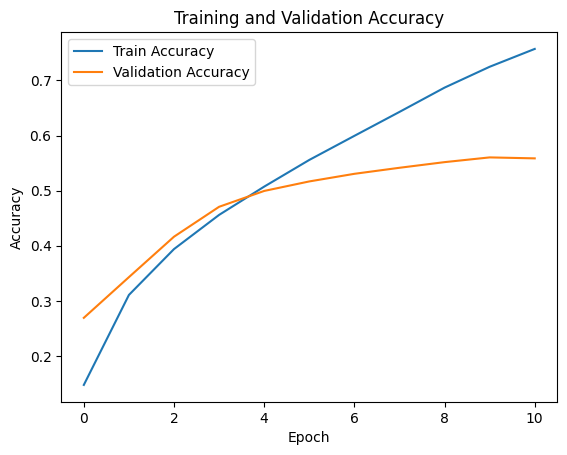

In [ ]:
visualize_accuracy(train_accs, eval_accs)

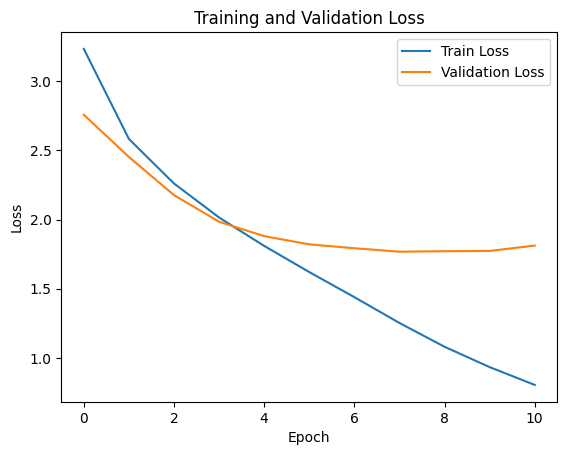

In [ ]:
visualize_loss(train_losses, eval_losses)

# **08. Inference**

In [ ]:
# load model
checkpoint = torch.load(
    "/content/drive/MyDrive/SGU_Courses/Pattern_Recognition_HK1_26_27/models/AlexNet/AlexNet_model_checkpoint.pth"
)
model = AlexNet(num_classes=num_classes)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

AlexNet(
  (extract_feature): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=9216, out_features=4096, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5):

In [ ]:
# Inference one test sample

def inference_random_sample(model, test_dir, transform, class_names=None):
    # 1. Lấy danh sách ảnh trong test
    test_dir = Path(test_dir)
    image_paths = [
        p for p in test_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    if not image_paths:
        raise ValueError(f"Không tìm thấy ảnh trong {test_dir}")

    # 2. Chọn ngẫu nhiên 1 ảnh
    image_path = random.choice(image_paths)
    image = Image.open(image_path).convert("RGB")

    # 3. Tiền xử lý ảnh và thêm batch dimension
    input_tensor = transform(image).unsqueeze(0)

    # 4. Chạy inference
    device = next(model.parameters()).device
    input_tensor = input_tensor.to(device)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)

        confidence, predicted_idx = probabilities.max(dim=1)

    predicted_idx = predicted_idx.item()
    confidence = confidence.item()

    # 5. Hiển thị kết quả
    if class_names is not None:
        predicted_label = class_names[predicted_idx]
    else:
        predicted_label = str(predicted_idx)

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence:.2%}"
    )
    plt.show()

    print(f"Image: {image_path.name}")
    print(f"Predicted class: {predicted_label}")
    print(f"Confidence: {confidence:.2%}")

    return {
        "image_path": str(image_path),
        "predicted_idx": predicted_idx,
        "predicted_label": predicted_label,
        "confidence": confidence,
    }


In [ ]:
class_names = [value for key, value in labels_dict.items()]
class_names

['Đầm / Váy Nữ',
 'Đầm Dáng Dài / Maxi',
 'Áo Thun / Áo Phông',
 'Áo Nỉ, Hoodie & Áo Len',
 'Quần Jeans Nữ',
 'Nhẫn & Trang Sức',
 'Bông Tai / Khuyên Tai',
 'Mũ & Nón Thời Trang',
 'Ví & Bóp Tiền',
 'Vali & Túi Du Lịch',
 'Ốp Lưng & Phụ Kiện Điện Thoại',
 'Điện Thoại & Máy Tính Bảng',
 'Đồng Hồ Treo Tường & Để Bàn',
 'Đồ Dùng Cho Bé Ăn Dặm',
 'Nồi Cơm Điện & Bếp Điện',
 'Cà Phê & Dụng Cụ Pha Chế',
 'Giày Đế Bằng & Giày Búp Bê',
 'Giày Cao Gót & Sandal Nữ',
 'Tủ Lạnh & Máy Lạnh',
 'Thẻ Nhớ & USB Lưu Trữ',
 'Bàn Ghế & Nội Thất',
 'Dụng Cụ Thể Thao Vợt',
 'Mũ Bảo Hiểm & Đồ Bảo Hộ',
 'Găng Tay Thời Trang & Bảo Hộ',
 'Đồng Hồ Đeo Tay',
 'Thắt Lưng / Dây Nịt',
 'Tai Nghe & Thiết Bị Âm Thanh',
 'Mô Hình Xe & Đồ Chơi Phương Tiện',
 'Áo Khoác Nam Nữ',
 'Quần Nam',
 'Giày Thể Thao & Sneaker',
 'Bánh Kẹo & Đồ Ăn Vặt',
 'Khẩu Trang & Vật Tư Y Tế',
 'Gel Sát Khuẩn & Nước Rửa Tay',
 'Mỹ Phẩm & Trang Điểm',
 'Nước Hoa & Xịt Thơm',
 'Dụng Cụ Vệ Sinh & Sửa Chữa Nhà Cửa',
 'Laptop & Phụ Kiện Máy Tính',


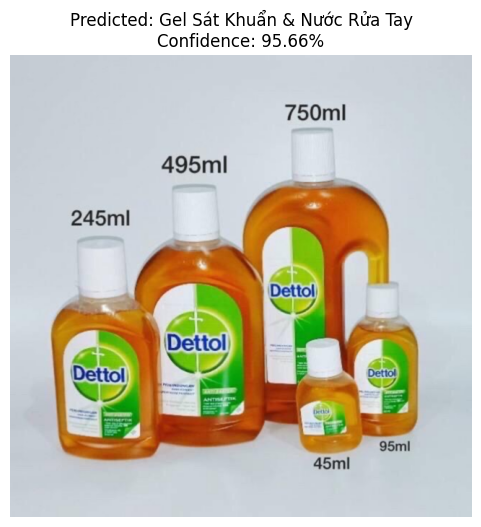

Image: 8e10d5292d6c59a0b199bcef59d46399.jpg
Predicted class: Gel Sát Khuẩn & Nước Rửa Tay
Confidence: 95.66%


In [ ]:
result = inference_random_sample(
    model=model,
    test_dir=data_path["test"],
    transform=test_transform,
    class_names=class_names
)